In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_DATA_FILE

df = pd.read_csv(RAW_DATA_FILE)

df.head()

,date,user_id,app_name,category,usage_minutes,sessions,notifications,hour_of_day,day_of_week,study_minutes,sleep_hours,daily_total_usage_minutes,daily_study_minutes,productivity_label
0,2026-08-01,U001,Instagram,Social,65,4,13,16,Saturday,26,7.9,495,214,Moderate
1,2026-08-01,U001,YouTube,Entertainment,200,25,100,23,Saturday,31,7.1,495,214,Moderate
2,2026-08-01,U001,WhatsApp,Social,85,5,17,22,Saturday,7,7.9,495,214,Moderate
3,2026-08-01,U001,Chrome,Utility,60,8,8,21,Saturday,46,8.1,495,214,Moderate
4,2026-08-01,U001,Notes,Productivity,42,3,10,8,Saturday,49,6.0,495,214,Moderate


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       2700 non-null   str    
 1   user_id                    2700 non-null   str    
 2   app_name                   2700 non-null   str    
 3   category                   2700 non-null   str    
 4   usage_minutes              2700 non-null   int64  
 5   sessions                   2700 non-null   int64  
 6   notifications              2700 non-null   int64  
 7   hour_of_day                2700 non-null   int64  
 8   day_of_week                2700 non-null   str    
 9   study_minutes              2700 non-null   int64  
 10  sleep_hours                2700 non-null   float64
 11  daily_total_usage_minutes  2700 non-null   int64  
 12  daily_study_minutes        2700 non-null   int64  
 13  productivity_label         2700 non-null   str    
dtypes: 

In [6]:
df.describe()

,usage_minutes,sessions,notifications,hour_of_day,study_minutes,sleep_hours,daily_total_usage_minutes,daily_study_minutes
count,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000
mean,68.788889,6.366667,17.984444,16.522222,47.707037,6.975333,412.733333,286.242222
std,47.654266,5.770882,16.380020,5.251851,36.518889,1.007879,86.270356,63.276710
min,5.000000,1.000000,0.000000,8.000000,0.000000,4.000000,199.000000,134.000000
25%,33.000000,2.000000,7.000000,13.000000,22.000000,6.300000,348.000000,240.000000
50%,56.000000,5.000000,13.000000,19.000000,39.000000,7.000000,412.500000,288.000000
75%,89.000000,9.000000,24.000000,21.000000,58.000000,7.600000,469.000000,329.000000
max,223.000000,39.000000,110.000000,23.000000,149.000000,10.000000,698.000000,483.000000


In [7]:
df["productivity_label"].value_counts()

productivity_label
Moderate      2036
Productive     496
Distracted     168
Name: count, dtype: int64

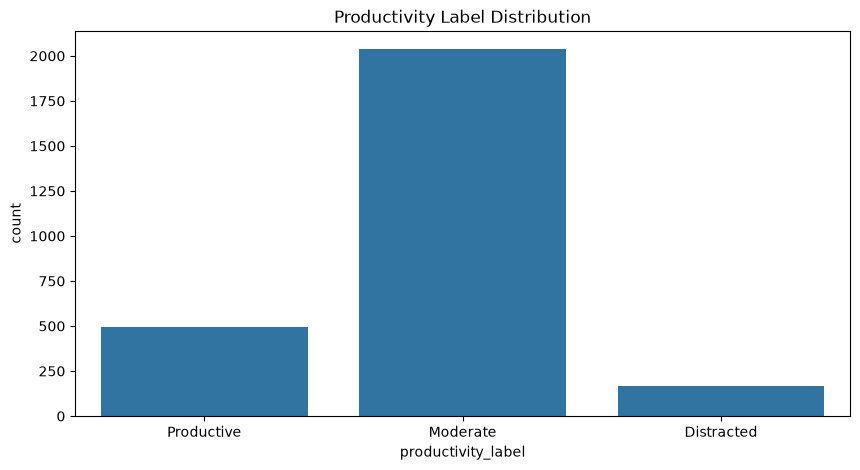

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="productivity_label",
    order=["Productive", "Moderate", "Distracted"]
)
plt.title("Productivity Label Distribution")
plt.show()

In [9]:
app_usage = (
    df.groupby("app_name")["usage_minutes"]
    .sum()
    .sort_values(ascending=False)
)

app_usage

app_name
YouTube      54056
Instagram    52219
Chrome       24682
WhatsApp     24308
Duolingo     15430
Notes        15035
Name: usage_minutes, dtype: int64

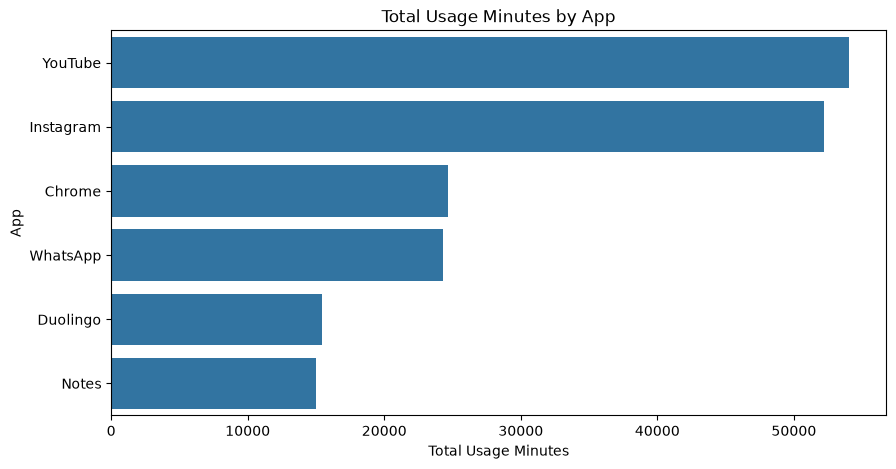

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(x=app_usage.values, y=app_usage.index)
plt.title("Total Usage Minutes by App")
plt.xlabel("Total Usage Minutes")
plt.ylabel("App")
plt.show()